In [ ]:
import numpy as np
import pandas as pd

def apply_full_costs(
    df,
    initial_capital=100_000,
    price_col="Close",
    commission_per_share=0.0035,
    annual_financing_rate=0.05,
    annual_short_borrow_rate=0.10,
    periods_per_year=252
):
    df = df.copy()

    # -----------------------------------
    # 1. Gross strategy returns and equity
    # -----------------------------------

    df["asset_return"] = df[price_col].pct_change()

    df["raw_strategy_return"] = (
        df["position"].shift(1)
        * df["asset_return"]
    )

    df["gross_equity"] = (
        initial_capital
        * (1 + df["raw_strategy_return"]).cumprod()
    )

    # -----------------------------------
    # 2. Equity available before today's trade
    # -----------------------------------

    df["equity_prior"] = df["gross_equity"].shift(1)
    df["equity_prior"] = df["equity_prior"].fillna(initial_capital)

    # -----------------------------------
    # 3. Share-based commission model
    # -----------------------------------

    df["dollar_position"] = (
        df["position"].shift(1)
        * df["equity_prior"]
    )

    df["shares"] = (
        df["dollar_position"]
        / df[price_col]
    )

    df["shares_traded"] = (
        df["shares"]
        .diff()
        .abs()
        .fillna(0)
    )

    df["commission_cost"] = (
        df["shares_traded"]
        * commission_per_share
    )

    # -----------------------------------
    # 4. Financing cost for leveraged longs
    # -----------------------------------

    daily_loan_rate = (
        annual_financing_rate
        / periods_per_year
    )

    df["position_prior"] = df["position"].shift(1)

    df["is_new_trade"] = (
        df["position_prior"]
        .diff()
        .fillna(df["position_prior"])
        != 0
    )

    df["leverage_factor"] = (
        df["position_prior"] - 1
    ).clip(lower=0)

    df["initial_debt"] = np.where(
        df["is_new_trade"],
        df["leverage_factor"]
        * df["equity_prior"],
        0
    )

    debt = (
        pd.Series(df["initial_debt"])
        .replace(0, np.nan)
    )

    debt = np.where(
        df["leverage_factor"] == 0,
        0,
        debt
    )

    df["cash_borrowed"] = (
        pd.Series(debt)
        .ffill()
        .fillna(0)
        .values
    )

    df["long_financing_cost"] = (
        df["cash_borrowed"]
        * daily_loan_rate
    )

    # -----------------------------------
    # 5. Short borrow costs
    # -----------------------------------

    daily_short_rate = (
        annual_short_borrow_rate
        / periods_per_year
    )

    df["short_exposure_value"] = np.where(
        df["position_prior"] < 0,
        np.abs(df["position_prior"])
        * df["equity_prior"],
        0
    )

    df["short_borrow_cost"] = (
        df["short_exposure_value"]
        * daily_short_rate
    )

    # -----------------------------------
    # 6. Convert dollar costs into return drag
    # -----------------------------------

    df["commission_drag"] = (
        df["commission_cost"]
        / df["equity_prior"]
    )

    df["financing_drag"] = (
        df["long_financing_cost"]
        / df["equity_prior"]
    )

    df["borrow_drag"] = (
        df["short_borrow_cost"]
        / df["equity_prior"]
    )

    # -----------------------------------
    # 7. Net returns after costs
    # -----------------------------------

    df["net_strategy_return"] = (
        df["raw_strategy_return"]
        - df["commission_drag"]
        - df["financing_drag"]
        - df["borrow_drag"]
    )

    df["net_equity"] = (
        initial_capital
        * (1 + df["net_strategy_return"])
        .cumprod()
    )

    return df

In [ ]:
import yfinance as yf

# Download data
df = yf.download("SPY", start="2015-01-01", auto_adjust=True)

if isinstance(df.columns, pd.MultiIndex):
  df.columns = df.columns.get_level_values(0)

[*********************100%***********************]  1 of 1 completed


In [ ]:
# Moving averages
df["MA50"] = df["Close"].rolling(50).mean()
df["MA200"] = df["Close"].rolling(200).mean()

# Trading signal
# df["position"] = (df["MA50"] > df["MA200"]).astype(int)

# In order to capture financing costs and short borrowing costs,
# We'll use 2x leverage when long, and allow short-selling
df["position"] = np.where(df["MA50"] > df["MA200"], 2, -1)

In [ ]:
df2 = apply_full_costs(df)

<Axes: xlabel='Date'>

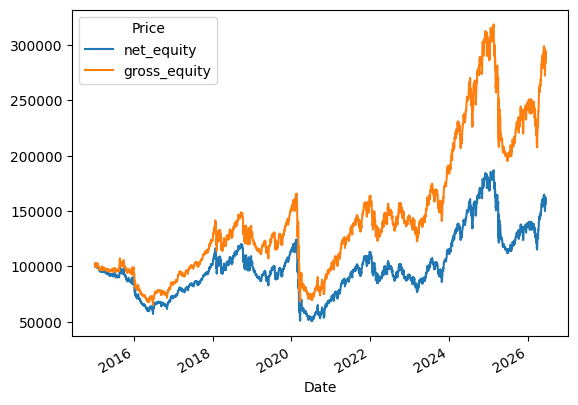

In [ ]:
df2[["net_equity", "gross_equity"]].plot()